# Step 5: Train/Test Split & Class Imbalance Handling

Goal: split the provider-level feature table into train/test sets, then
compare two imbalance-handling methodologies — **SMOTE oversampling** and
**random undersampling** — applied **only to the training set**.

Two rules carried over from `04b_feature_engineering.ipynb` and documented
in `bt4012_handover (internal)/human.md`:
1. **Split by Provider, not claim.** Not actually an extra step here —
   `provider_features.csv` is already one row per provider, so an ordinary
   stratified `train_test_split` on it *is* a provider-level split with no
   leakage risk (no provider can appear in both halves, since each row is a
   distinct provider).
2. **Imbalance handling happens after splitting, and only on the training
   set.** Resampling the test set would let synthetic/duplicated rows leak
   into evaluation and make the test metrics meaningless.

> **How this notebook relates to the final models.** The split here (4,328 / 1,082 providers) is the one
> every model uses. The SMOTE and undersampled files saved below were an **exploratory** comparison and are
> **not** used by the final models: `06b` and `06c` train on `provider_features_train.csv` and apply class
> weighting or SMOTE **inside each cross-validation fold** instead (undersampling was not carried forward).

In [1]:
import sys
sys.path.append('..')

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

pd.set_option('display.max_columns', 40)
sns.set_style('whitegrid')
RANDOM_STATE = 42

provider_features = pd.read_csv('../data/processed/provider_features.csv')
feature_sets = json.load(open('../data/processed/feature_sets.json'))
full_features = feature_sets['full_features']
logistic_features = feature_sets['logistic_features']

provider_features.shape

(5410, 28)

## Train/Test Split

Stratified on `PotentialFraud` so both splits preserve the ~9.35% fraud
rate — an unstratified split risks a test set with an unrepresentative
(or even zero) number of fraud providers, given how few there are
(506 total).

In [2]:
train_df, test_df = train_test_split(
    provider_features,
    test_size=0.2,
    stratify=provider_features['PotentialFraud'],
    random_state=RANDOM_STATE,
)

print(f'Train: {train_df.shape[0]} providers | Test: {test_df.shape[0]} providers')
print(f'Train fraud rate: {train_df["PotentialFraud"].mean():.4f}')
print(f'Test fraud rate:  {test_df["PotentialFraud"].mean():.4f}')

Train: 4328 providers | Test: 1082 providers
Train fraud rate: 0.0936
Test fraud rate:  0.0933


In [3]:
# Integrity checks: no provider leaks across the split, both halves non-trivial
train_providers = set(train_df['Provider'])
test_providers = set(test_df['Provider'])

print('Providers in both train and test (should be 0):', len(train_providers & test_providers))
print('Train + Test = Total:', len(train_providers) + len(test_providers) == len(provider_features))
print('Fraud providers in train:', train_df['PotentialFraud'].sum(), '| in test:', test_df['PotentialFraud'].sum())

Providers in both train and test (should be 0): 0
Train + Test = Total: True
Fraud providers in train: 405 | in test: 101


*Zero overlap confirmed, and both splits carry a meaningful number of fraud providers (not just 1-2) despite the 9.35% base rate — the stratification is doing its job.*

In [4]:
# Audit trail: which providers ended up in which split (not used as a
# model feature — Provider is dropped before any X/y matrix below).
split_audit = pd.concat([
    train_df[['Provider', 'PotentialFraud']].assign(Split='train'),
    test_df[['Provider', 'PotentialFraud']].assign(Split='test'),
])
split_audit.to_csv('../data/processed/train_test_provider_ids.csv', index=False)
split_audit['Split'].value_counts()

Split
train    4328
test     1082
Name: count, dtype: int64

## Baseline Class Distribution (Before Resampling)

Only the **training set** gets resampled — the test set stays exactly as
split above, for the entire rest of this notebook and into Step 6.

In [5]:
X_train = train_df[full_features].reset_index(drop=True)
y_train = train_df['PotentialFraud'].reset_index(drop=True)
X_test = test_df[full_features].reset_index(drop=True)
y_test = test_df['PotentialFraud'].reset_index(drop=True)

print('X_train:', X_train.shape, '| X_test:', X_test.shape)
y_train.value_counts()

X_train: (4328, 26) | X_test: (1082, 26)


PotentialFraud
0    3923
1     405
Name: count, dtype: int64

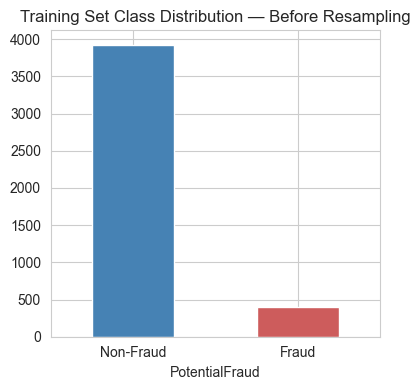

In [6]:
y_train.value_counts().plot(kind='bar', color=['steelblue', 'indianred'], figsize=(4, 4))
plt.xticks([0, 1], ['Non-Fraud', 'Fraud'], rotation=0)
plt.title('Training Set Class Distribution — Before Resampling')
plt.tight_layout()
plt.show()

## Resampling Helper

SMOTE generates synthetic minority-class rows by interpolating between
real ones in feature space, using Euclidean nearest neighbors — which is
scale-sensitive (a feature ranging 0-1,000 would dominate the distance
calculation over one ranging 0-1). Scaling with `StandardScaler` (fit on
the training set only) before resampling, then inverse-transforming back,
keeps the saved output on the original, interpretable feature scale —
consistent with `X_test`, which is never scaled here. Any model-specific
scaling (e.g. for logistic regression) is a Step 6 concern, not this one.

Random undersampling just drops real majority-class rows at random, so
scale doesn't matter for it — but it shares the same scale/unscale
plumbing here for a single, reusable function.

In [7]:
def resample_training_set(X, y, method, random_state=RANDOM_STATE):
    """
    method: 'smote' or 'undersample'. Returns (X_resampled, y_resampled)
    as a DataFrame/Series on the original feature scale.
    """
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    if method == 'smote':
        sampler = SMOTE(random_state=random_state)
    elif method == 'undersample':
        sampler = RandomUnderSampler(random_state=random_state)
    else:
        raise ValueError(f"Unknown method: {method!r}")

    X_res_scaled, y_res = sampler.fit_resample(X_scaled, y)
    X_res = pd.DataFrame(scaler.inverse_transform(X_res_scaled), columns=X.columns)
    y_res = pd.Series(y_res, name=y.name)
    return X_res, y_res

## Method 1: SMOTE Oversampling

In [8]:
X_train_smote, y_train_smote = resample_training_set(X_train, y_train, method='smote')

print(f'Before: {len(X_train)} rows ({y_train.sum()} fraud, {(y_train==0).sum()} non-fraud)')
print(f'After:  {len(X_train_smote)} rows ({y_train_smote.sum()} fraud, {(y_train_smote==0).sum()} non-fraud)')
y_train_smote.value_counts()

Before: 4328 rows (405 fraud, 3923 non-fraud)
After:  7846 rows (3923 fraud, 3923 non-fraud)


/Users/tanyumin/Downloads/bt4012_grp14/bt4012-group14-healthcare-fraud-detection/.bt4012grp/lib/python3.11/site-packages/sklearn/base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(


PotentialFraud
0    3923
1    3923
Name: count, dtype: int64

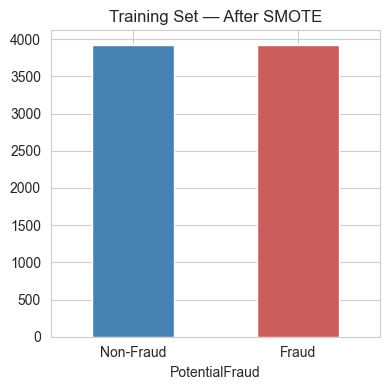

In [9]:
fig, ax = plt.subplots(figsize=(4, 4))
y_train_smote.value_counts().plot(kind='bar', color=['steelblue', 'indianred'], ax=ax)
ax.set_xticks([0, 1])
ax.set_xticklabels(['Non-Fraud', 'Fraud'], rotation=0)
ax.set_title('Training Set — After SMOTE')
plt.tight_layout()
plt.show()

**Sanity check**: synthetic rows should look like plausible interpolations
of real fraud providers, not nonsense (e.g. negative claim counts). Compare
summary statistics of the synthetic-heavy resampled set against the
original real fraud rows.

In [10]:
compare_cols = ['NumClaims', 'MaxClaimAmt', 'AvgLengthOfStayDays', 'TopProcedureCodeShare']
print('Original fraud rows (real only):')
print(X_train.loc[y_train == 1, compare_cols].describe().loc[['mean', 'min', 'max']])
print()
print('After SMOTE (real + synthetic fraud rows):')
print(X_train_smote.loc[y_train_smote == 1, compare_cols].describe().loc[['mean', 'min', 'max']])

Original fraud rows (real only):
        NumClaims    MaxClaimAmt  AvgLengthOfStayDays  TopProcedureCodeShare
mean   378.014815   43858.617284             5.302748               0.206019
min      1.000000     200.000000             0.000000               0.027778
max   8240.000000  125000.000000            13.666667               1.000000

After SMOTE (real + synthetic fraud rows):
        NumClaims    MaxClaimAmt  AvgLengthOfStayDays  TopProcedureCodeShare
mean   370.427131   42580.745247             5.170802               0.204507
min      1.000000     200.000000             0.000000               0.027778
max   8240.000000  125000.000000            13.666667               1.000000


*Means stay close and ranges don't blow out to implausible values (e.g. no negative claim counts) — SMOTE is interpolating sensibly within the existing fraud-provider feature space, not extrapolating into nonsense.*

## Method 2: Random Undersampling

In [11]:
X_train_under, y_train_under = resample_training_set(X_train, y_train, method='undersample')

print(f'Before: {len(X_train)} rows ({y_train.sum()} fraud, {(y_train==0).sum()} non-fraud)')
print(f'After:  {len(X_train_under)} rows ({y_train_under.sum()} fraud, {(y_train_under==0).sum()} non-fraud)')
y_train_under.value_counts()

Before: 4328 rows (405 fraud, 3923 non-fraud)
After:  810 rows (405 fraud, 405 non-fraud)


/Users/tanyumin/Downloads/bt4012_grp14/bt4012-group14-healthcare-fraud-detection/.bt4012grp/lib/python3.11/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Users/tanyumin/Downloads/bt4012_grp14/bt4012-group14-healthcare-fraud-detection/.bt4012grp/lib/python3.11/site-packages/sklearn/base.py:484: FutureWarning: `BaseEstimator._check_n_features` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_n_features` instead.
  warnings.warn(
/Users/tanyumin/Downloads/bt4012_grp14/bt4012-group14-healthcare-fraud-detection/.bt4012grp/lib/python3.11/site-packages/sklearn/base.py:493: FutureWarning: `BaseEstimator._check_feature_names` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_feature_names` instead.
  warnings.warn(


PotentialFraud
0    405
1    405
Name: count, dtype: int64

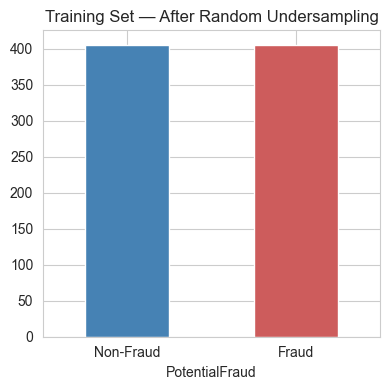

In [12]:
fig, ax = plt.subplots(figsize=(4, 4))
y_train_under.value_counts().plot(kind='bar', color=['steelblue', 'indianred'], ax=ax)
ax.set_xticks([0, 1])
ax.set_xticklabels(['Non-Fraud', 'Fraud'], rotation=0)
ax.set_title('Training Set — After Random Undersampling')
plt.tight_layout()
plt.show()

*Undersampling doesn't invent anything — it's a straight subset of real non-fraud providers, so every row here corresponds to an actual provider (unlike SMOTE's synthetic rows).*

## Side-by-Side Comparison

In [13]:
comparison = pd.DataFrame({
    'Original':    [len(X_train), (y_train == 0).sum(), (y_train == 1).sum(), y_train.mean()],
    'SMOTE':       [len(X_train_smote), (y_train_smote == 0).sum(), (y_train_smote == 1).sum(), y_train_smote.mean()],
    'Undersample': [len(X_train_under), (y_train_under == 0).sum(), (y_train_under == 1).sum(), y_train_under.mean()],
}, index=['Total Rows', 'Non-Fraud', 'Fraud', 'Fraud Rate']).round(4)
comparison

,Original,SMOTE,Undersample
Total Rows,4328.0000,7846.0,810.0
Non-Fraud,3923.0000,3923.0,405.0
Fraud,405.0000,3923.0,405.0
Fraud Rate,0.0936,0.5,0.5


**The core tradeoff**: SMOTE keeps every real non-fraud row and adds
synthetic fraud rows, so training data stays large but the minority class
is now synthetic-heavy (real fraud providers are a small fraction of the
"Fraud" rows after balancing). Undersampling keeps only real rows but
throws away most non-fraud data, shrinking the training set to roughly
2x the fraud count — a real risk of underfitting non-fraud patterns with
so little data. Neither is obviously "correct" — Step 6 should train on
both (plus the unresampled baseline, and optionally class-weighting as a
third, resampling-free alternative) and compare on the held-out test set,
not assume one wins going in.

## Saving Outputs for Step 6

In [14]:
test_df[['Provider'] + full_features + ['PotentialFraud']].to_csv('../data/processed/provider_features_test.csv', index=False)
train_df[['Provider'] + full_features + ['PotentialFraud']].to_csv('../data/processed/provider_features_train.csv', index=False)

X_train_smote.assign(PotentialFraud=y_train_smote).to_csv('../data/processed/provider_features_train_smote.csv', index=False)
X_train_under.assign(PotentialFraud=y_train_under).to_csv('../data/processed/provider_features_train_undersampled.csv', index=False)

print('Saved: provider_features_{train,test}.csv (raw split, all 26 features + Provider + label)')
print('Saved: provider_features_train_{smote,undersampled}.csv (resampled, no Provider column — synthetic/subset rows)')
print('Saved: train_test_provider_ids.csv (audit trail of which Provider went to which split)')

Saved: provider_features_{train,test}.csv (raw split, all 26 features + Provider + label)
Saved: provider_features_train_{smote,undersampled}.csv (resampled, no Provider column — synthetic/subset rows)
Saved: train_test_provider_ids.csv (audit trail of which Provider went to which split)


**Note for Step 6**: all four training variants (`original` = `X_train`/`y_train`
from this notebook, `smote`, `undersampled`) and the untouched test set use
the full 26-feature set. For logistic regression specifically, select the
22-column `logistic_features` list (loaded from `feature_sets.json` above)
from any of these same tables — don't re-run SMOTE/undersampling separately
per feature set, since that would generate numerically inconsistent
synthetic rows for the same conceptual example under each feature list.

## Summary

- Split `provider_features.csv` (5,410 providers) into train (4,328) /
  test (1,082) via a stratified 80/20 split on `PotentialFraud` — already
  provider-level by construction, no additional grouping needed. Verified
  zero provider overlap between splits.
- Resampling applied **only to the training set**, using two methods:
  - **SMOTE**: synthetic fraud rows generated via scaled nearest-neighbor
    interpolation (scaled for distance correctness, then inverse-transformed
    back to the original feature scale for storage). Sanity-checked that
    synthetic rows stay within plausible real-world ranges.
  - **Random undersampling**: real non-fraud rows dropped at random to
    match the fraud count — no synthetic data, but a much smaller training
    set.
- Both resampled training sets, the unresampled training set, and the
  untouched test set are saved to `data/processed/` for Step 6, along with
  a `train_test_provider_ids.csv` audit trail.
- **Recommendation for Step 6**: train on all three training variants
  (original, SMOTE, undersampled) and compare on the same held-out test
  set — don't assume one resampling method wins without evidence. Class
  weighting (e.g. `class_weight="balanced"`) is a resampling-free
  alternative worth trying alongside these, not implemented here since it's
  a model hyperparameter rather than a data transformation.